In [ ]:

# WEEK 6 — HEALTHCONNECT RWANDA
# Combined Google Drive setup + dataset inventory

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import zipfile
import pandas as pd
import os

MYDRIVE = Path('/content/drive/MyDrive')
BASE = MYDRIVE / 'Week6_HealthConnect'
BASE.mkdir(parents=True, exist_ok=True)

# 1. Locate ZIP files in the expected folder or MyDrive root
zips = list(BASE.glob('*.zip'))
if not zips:
    zips = list(MYDRIVE.glob('*.zip'))

# Extract ZIP files into the project folder
for z in zips:
    target = BASE / z.stem
    if not target.exists() or not any(target.iterdir()):
        target.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(z, 'r') as archive:
            archive.extractall(target)
        print(f'Extracted: {z.name}')

# 2. Find datasets (including datasets already extracted)
extensions = {'.csv', '.xlsx', '.xls', '.parquet'}
files = [
    p for p in BASE.rglob('*')
    if p.is_file() and p.suffix.lower() in extensions
]

# If the expected folder is empty, search MyDrive for datasets
if not files:
    files = [
        p for p in MYDRIVE.rglob('*')
        if p.is_file()
        and p.suffix.lower() in extensions
        and 'Week6_HealthConnect' in str(p)
    ]

if not files:
    raise FileNotFoundError(
        'No CSV/Excel/Parquet datasets found. '
        'Check that your upload is inside MyDrive/Week6_HealthConnect '
        'or put the ZIP directly in MyDrive, then rerun.'
    )

# 3. Read datasets and generate a compact inventory
datasets = {}
inventory = []

for path in files:
    try:
        if path.suffix.lower() == '.csv':
            df = pd.read_csv(path, low_memory=False)
        elif path.suffix.lower() in {'.xlsx', '.xls'}:
            df = pd.read_excel(path)
        else:
            df = pd.read_parquet(path)

        name = path.stem
        datasets[name] = df

        inventory.append({
            'file': str(path.relative_to(MYDRIVE)),
            'dataset': name,
            'rows': len(df),
            'columns': len(df.columns),
            'missing_cells': int(df.isna().sum().sum()),
            'duplicate_rows': int(df.duplicated().sum()),
            'column_names': ', '.join(map(str, df.columns))
        })

    except Exception as e:
        print(f'SKIPPED {path.name}: {e}')

inventory_df = pd.DataFrame(inventory)

print(f'\nDATASETS LOADED: {len(datasets)}')
display(
    inventory_df[
        ['dataset', 'rows', 'columns', 'missing_cells', 'duplicate_rows']
    ].sort_values('dataset')
)

# 4. Save the inventory for documentation
inventory_path = BASE / 'week6_data_inventory.csv'
inventory_df.to_csv(inventory_path, index=False)
print(f'\nInventory saved to: {inventory_path}')

# 5. Preview all dataset columns for planning the ML pipeline
for name, df in datasets.items():
    print(f'\n--- {name} | {df.shape} ---')
    print(list(df.columns))
    print(df.head(2).to_string(index=False))


Mounted at /content/drive

DATASETS LOADED: 38


,dataset,rows,columns,missing_cells,duplicate_rows
11,HCCountries,1,6,0,0
12,HC_Administrative_Staff,80,10,0,0
13,HC_Beds,2000,3,0,0
14,HC_Billing,60000,4,0,0
15,HC_Clinical_Transactions,5000,7,0,0
16,HC_Departments,200,3,0,0
17,HC_Diagnoses,60000,4,0,0
18,HC_Districts,30,3,0,0
19,HC_Doctor,350,10,0,0
20,HC_Facility_Master_Data,200,3,0,0



Inventory saved to: /content/drive/MyDrive/Week6_HealthConnect/week6_data_inventory.csv

--- week6_data_inventory | (27, 7) ---
['file', 'dataset', 'rows', 'columns', 'missing_cells', 'duplicate_rows', 'column_names']
                                                                                         file                 dataset  rows  columns  missing_cells  duplicate_rows                                                                                                 column_names
            Week6_HealthConnect/analystlabweek6dataset/analystlabweek6dataset/HCCountries.csv             HCCountries     1        6              0               0                                                         CountryID, CountryName, ISO2, ISO3, Currency, Region
Week6_HealthConnect/analystlabweek6dataset/analystlabweek6dataset/HC_Administrative_Staff.csv HC_Administrative_Staff    80       10              0               0 StaffID, FirstName, LastName, Role, Department, Specialty, FacilityID, 

In [ ]:
# =============================================================
# WEEK 6 — ROBUST FIX + CONTINUE REMAINING PIPELINE
# HealthConnect Rwanda
# =============================================================

import os
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.ensemble import (
    RandomForestClassifier, RandomForestRegressor, IsolationForest
)
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# ---------- 1. Output folder ----------
OUT = globals().get(
    "OUT",
    "/content/drive/MyDrive/Week6_HealthConnect/results"
)
os.makedirs(OUT, exist_ok=True)

RANDOM_STATE = 42

# ---------- 2. Robust missing-value sanitation ----------
def sanitize_dataframe(df):
    df = df.copy()

    for col in df.columns:
        s = df[col]

        if pd.api.types.is_numeric_dtype(s.dtype):
            # Convert nullable numeric extension types to float/np.nan
            df[col] = pd.to_numeric(s, errors="coerce").astype(float)
        else:
            # Convert strings/categories and replace pd.NA with np.nan
            df[col] = s.astype(object)
            df[col] = df[col].where(pd.notna(df[col]), np.nan)

    return df

# ---------- 3. Robust preprocessing ----------
def make_preprocessor(X):
    X = sanitize_dataframe(X)

    numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = [c for c in X.columns if c not in numeric_cols]

    transformers = []

    if numeric_cols:
        numeric_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
        transformers.append(("numeric", numeric_pipe, numeric_cols))

    if categorical_cols:
        categorical_pipe = Pipeline([
            ("imputer", SimpleImputer(
                strategy="constant", fill_value="Missing"
            )),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore", sparse_output=False
            ))
        ])
        transformers.append(
            ("categorical", categorical_pipe, categorical_cols)
        )

    if not transformers:
        raise ValueError("No usable predictor columns were found.")

    return ColumnTransformer(transformers, remainder="drop")

# Ensure the existing classifier function uses the corrected preprocessor.
# This cell deliberately does not rerun the two completed classification tasks.

# ---------- 4. Recover the integrated dataset ----------
if "master" not in globals():
    # FIXED: Look directly in OUT where the file is verified to exist
    integrated_path = os.path.join(
        OUT,
        "cleaned_feature_engineered_appointments.csv"
    )
    if not os.path.exists(integrated_path):
        # Fallback to parent directory just in case
        integrated_path_alt = os.path.join(
            os.path.dirname(OUT),
            "cleaned_feature_engineered_appointments.csv"
        )
        if os.path.exists(integrated_path_alt):
            integrated_path = integrated_path_alt
        else:
            raise FileNotFoundError(
                "Cannot find the integrated dataset. Expected in: " + integrated_path
            )
    master = pd.read_csv(integrated_path)

master = sanitize_dataframe(master)
print("Integrated dataset:", master.shape)

# ---------- 5. High-risk screening proxy classification ----------
# This is a rule-generated educational proxy, NOT a clinically validated
# patient-risk model.

def find_col(df, candidates):
    lookup = {c.lower().replace("_", "").replace(" ", ""): c
              for c in df.columns}
    for candidate in candidates:
        key = candidate.lower().replace("_", "").replace(" ", "")
        if key in lookup:
            return lookup[key]
    return None

target = "HighRiskScreeningProxy"

if target not in master.columns:
    age_col = find_col(master, ["Age"])
    chronic_col = find_col(
        master, ["HasChronicCondition", "ChronicCondition",
                 "Has_Chronic_Condition"]
    )
    severity_col = find_col(master, ["Severity", "SeverityScore"])

    if age_col is None:
        raise ValueError(
            "Cannot create screening proxy: age column was not found."
        )

    age = pd.to_numeric(master[age_col], errors="coerce").fillna(0)
    high_risk = age >= 65

    if chronic_col:
        chronic = master[chronic_col].astype(str).str.lower().isin(
            ["1", "true", "yes", "y"]
        )
        high_risk = high_risk | chronic

    if severity_col:
        severity = pd.to_numeric(
            master[severity_col], errors="coerce"
        ).fillna(0)
        high_risk = high_risk | (severity >= 3)

    master[target] = np.where(high_risk, "High", "Standard")

# Drop direct rule ingredients from predictors to reduce direct label leakage.
exclude = {
    target, "AppointmentID", "PatientID", "DoctorID", "FacilityID",
    "Date", "AppointmentDate", "DateOfBirth", "Age", "Severity",
    "SeverityScore", "HasChronicCondition", "Has_Chronic_Condition",
    "ChronicCondition"
}
risk_features = [
    c for c in master.columns
    if c not in exclude and master[c].nunique(dropna=True) > 1
]
risk_data = master[risk_features + [target]].dropna(subset=[target]).copy()
risk_data = sanitize_dataframe(risk_data)

X = risk_data[risk_features]
y = risk_data[target].astype(str)

if y.nunique() >= 2 and len(risk_data) >= 20:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE,
        stratify=y if y.value_counts().min() >= 2 else None
    )

    models = {
        "Logistic Regression": LogisticRegression(
            max_iter=1000, class_weight="balanced"
        ),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=8, random_state=RANDOM_STATE,
            class_weight="balanced"
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=150, random_state=RANDOM_STATE,
            class_weight="balanced", n_jobs=-1
        )
    }

    risk_results = []
    best_score = -1
    best_model = None
    best_name = None
    best_pred = None

    for name, estimator in models.items():
        pipe = Pipeline([
            ("preprocessor", make_preprocessor(X_train)),
            ("model", estimator)
        ])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)

        score = f1_score(
            y_test, pred, average="weighted", zero_division=0
        )
        risk_results.append({
            "Task": "High Risk Screening Proxy",
            "Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision_weighted": precision_score(
                y_test, pred, average="weighted", zero_division=0
            ),
            "Recall_weighted": recall_score(
                y_test, pred, average="weighted", zero_division=0
            ),
            "F1_weighted": score
        })

        if score > best_score:
            best_score = score
            best_model = pipe
            best_name = name
            best_pred = pred

    print("\nHigh Risk Screening Proxy — best model:", best_name)
    print(classification_report(
        y_test, best_pred, zero_division=0
    ))

    pd.DataFrame(risk_results).to_csv(
        os.path.join(OUT, "high_risk_proxy_model_comparison.csv"),
        index=False
    )
    pd.DataFrame(
        confusion_matrix(y_test, best_pred, labels=best_model.classes_),
        index=best_model.classes_,
        columns=best_model.classes_
    ).to_csv(os.path.join(OUT, "confusion_matrix_high_risk_proxy.csv"))

    saved_models = globals().get("saved_models", {})
    saved_models["High Risk Screening Proxy"] = best_model
    globals()["saved_models"] = saved_models
else:
    print("Skipped risk classification: target has fewer than 2 usable classes.")

# ---------- 6. Revenue regression ----------
# Honest available target: appointment-level billing amount,
# not a validated future monthly revenue forecast.

billing_col = find_col(
    master, ["TotalBillingAmount", "BillingAmount",
             "TotalAmount", "AmountBilled", "Billing_Total"]
)

if billing_col is not None:
    revenue_df = master.copy()
    revenue_df[billing_col] = pd.to_numeric(
        revenue_df[billing_col], errors="coerce"
    )
    revenue_df = revenue_df.dropna(subset=[billing_col])

    if len(revenue_df) >= 30:
        drop_cols = {
            billing_col, "AppointmentID", "PatientID", "DoctorID",
            "FacilityID", "Date", "AppointmentDate"
        }
        # Remove other direct billing/payment aggregates where present.
        drop_cols.update([
            c for c in revenue_df.columns
            if any(term in c.lower() for term in [
                "paymentamount", "totalpayment", "billingamount"
            ]) and c != billing_col
        ])

        reg_features = [
            c for c in revenue_df.columns
            if c not in drop_cols
            and revenue_df[c].nunique(dropna=True) > 1
        ]

        Xr = sanitize_dataframe(revenue_df[reg_features])
        yr = pd.to_numeric(revenue_df[billing_col], errors="coerce")
        valid = yr.notna()
        Xr, yr = Xr.loc[valid], yr.loc[valid]

        X_train, X_test, y_train, y_test = train_test_split(
            Xr, yr, test_size=0.2, random_state=RANDOM_STATE
        )

        regression_results = []
        best_reg = None
        best_reg_name = None
        best_mae = float("inf")

        for name, estimator in {
            "Linear Regression": LinearRegression(),
            "Random Forest Regressor": RandomForestRegressor(
                n_estimators=120, random_state=RANDOM_STATE, n_jobs=-1,
                min_samples_leaf=2
            )
        }.items():
            pipe = Pipeline([
                ("preprocessor", make_preprocessor(X_train)),
                ("model", estimator)
            ])
            pipe.fit(X_train, y_train)
            pred = pipe.predict(X_test)

            mae = mean_absolute_error(y_test, pred)
            regression_results.append({
                "Target": "Appointment-level billing amount",
                "Model": name,
                "MAE": mae,
                "RMSE": float(np.sqrt(mean_squared_error(y_test, pred))),
                "R2": r2_score(y_test, pred)
            })

            if mae < best_mae:
                best_mae = mae
                best_reg = pipe
                best_reg_name = name

        pd.DataFrame(regression_results).to_csv(
            os.path.join(OUT, "regression_metrics.csv"), index=False
        )
        print("\nRegression results:")
        print(pd.DataFrame(regression_results).to_string(index=False))
        print("Best regression model by MAE:", best_reg_name)
    else:
        print("Skipped regression: insufficient billing records.")
else:
    print("Billing amount column not found; regression skipped.")

# ---------- 7. Patient clustering ----------
patient_df = globals().get("patients", None)
if patient_df is None:
    patient_df = globals().get("datasets", {}).get("HC_Patients", None)

if patient_df is not None:
    patient_df = sanitize_dataframe(patient_df)
    numeric_candidates = [
        c for c in patient_df.select_dtypes(include=np.number).columns
        if c.lower() in [
            "age", "bmi", "heightcm", "weightkg", "height", "weight"
        ]
    ]

    if len(numeric_candidates) >= 2:
        pdata = patient_df[numeric_candidates].copy()
        pdata = pdata.replace([np.inf, -np.inf], np.nan)
        pdata = pdata.fillna(pdata.median()).fillna(0)

        scaler = StandardScaler()
        scaled = scaler.fit_transform(pdata)

        k = min(3, max(2, len(pdata) // 100))
        k = min(k, len(pdata))
        if k >= 2:
            patient_clusters = KMeans(
                n_clusters=k, random_state=RANDOM_STATE, n_init=10
            ).fit_predict(scaled)
            out_patients = patient_df.copy()
            out_patients["PatientCluster"] = patient_clusters
            out_patients.to_csv(
                os.path.join(OUT, "patient_clusters.csv"), index=False
            )
            print("\nPatient clustering saved.")
    else:
        print("Patient clustering skipped: insufficient numeric profile features.")
else:
    print("Patient dataset not found; patient clustering skipped.")

# ---------- 8. Facility clustering ----------
facility_df = globals().get("datasets", {}).get(
    "HC_Facility_Master_Data", None
)
clinical_df = globals().get("datasets", {}).get(
    "HC_Clinical_Transactions", None
)

if facility_df is not None and clinical_df is not None:
    facility_df = sanitize_dataframe(facility_df)
    clinical_df = sanitize_dataframe(clinical_df)
    facility_key = find_col(facility_df, ["FacilityID"])
    clinical_facility_key = find_col(clinical_df, ["FacilityID"])

    if facility_key and clinical_facility_key:
        counts = clinical_df.groupby(clinical_facility_key).size().rename(
            "VisitCount"
        )
        fcluster_df = facility_df.merge(
            counts, left_on=facility_key, right_index=True, how="left"
        )
        fcluster_df["VisitCount"] = fcluster_df["VisitCount"].fillna(0)

        numeric_cols = fcluster_df.select_dtypes(
            include=np.number
        ).columns.tolist()
        numeric_cols = [
            c for c in numeric_cols if fcluster_df[c].nunique() > 1
        ]

        if numeric_cols and len(fcluster_df) >= 3:
            vals = fcluster_df[numeric_cols].replace(
                [np.inf, -np.inf], np.nan
            )
            vals = vals.fillna(vals.median()).fillna(0)
            scaled = StandardScaler().fit_transform(vals)
            k = min(3, len(fcluster_df))
            fcluster_df["FacilityCluster"] = KMeans(
                n_clusters=k, random_state=RANDOM_STATE, n_init=10
            ).fit_predict(scaled)
            fcluster_df.to_csv(
                os.path.join(OUT, "facility_clusters.csv"), index=False
            )
            print("Facility clustering saved.")
else:
    print("Facility clustering skipped: required tables unavailable.")

# ---------- 9. Billing anomaly detection ----------
if billing_col is not None and billing_col in master.columns:
    bill = pd.to_numeric(master[billing_col], errors="coerce")
    valid_bill = bill.notna() & np.isfinite(bill)

    if valid_bill.sum() >= 20:
        values = bill.loc[valid_bill].to_numpy().reshape(-1, 1)
        iso = IsolationForest(
            contamination=0.03, random_state=RANDOM_STATE
        )
        flags = iso.fit_predict(values)

        anomaly_df = master.loc[valid_bill].copy()
        anomaly_df["BillingAnomalyFlag"] = np.where(flags == -1, 1, 0)
        anomaly_df.to_csv(
            os.path.join(OUT, "billing_anomaly_detection.csv"), index=False
        )
        print(
            "\nBilling anomalies flagged:",
            int((flags == -1).sum())
        )
else:
    print("Billing anomaly detection skipped: billing column unavailable.")

# ---------- 10. Consolidate classification metrics ----------
# Keep prior completed task results if they exist; add risk results.
existing_path = os.path.join(OUT, "classification_model_comparison.csv")
if os.path.exists(existing_path):
    old = pd.read_csv(existing_path)
else:
    old = pd.DataFrame()

new_path = os.path.join(OUT, "high_risk_proxy_model_comparison.csv")
if os.path.exists(new_path):
    new = pd.read_csv(new_path)
    combined = pd.concat([old, new], ignore_index=True)
    keys = [c for c in ["Task", "Model"] if c in combined.columns]
    if keys:
        combined = combined.drop_duplicates(subset=keys, keep="last")
    combined.to_csv(existing_path, index=False)

# ---------- 11. Save limitations and completion summary ----------
limitations = """
HEALTHCONNECT RWANDA WEEK 6 — DATA AND MODEL LIMITATIONS

1. These are educational/synthetic datasets; outputs are not clinical advice.
2. HighRiskScreeningProxy is a rule-generated screening label, not a validated
   clinical outcome. Its model metrics must not be presented as clinical validity.
3. No explicit hospital-admission outcome column was identified.
4. No length-of-stay target or dedicated laboratory-results dataset was identified.
5. Revenue regression predicts appointment-level billing amount when available;
   it is not a validated forecast of future monthly facility revenue.
6. Patient satisfaction labels are derived from feedback ratings; performance
   may be weak and should be reported honestly.
7. Billing anomaly flags indicate unusual amounts, not confirmed fraud or errors.
8. Clusters are exploratory groupings, not medical diagnoses or quality rankings.
9. Any model with low performance should be reported as a limitation, not hidden.
10. Do not claim SHAP/LIME explanations unless those analyses have actually run.
11. No reliable distance-to-facility calculation should be claimed without
    usable patient/facility coordinates.
"""
with open(os.path.join(OUT, "limitations_and_ethics.txt"), "w") as f:
    f.write(limitations.strip())

master.to_csv(
    os.path.join(OUT, "cleaned_feature_engineered_appointments.csv"),
    index=False
)

print("\n" + "=" * 60)
print("CONTINUATION CELL FINISHED")
print("Outputs folder:", OUT)
print("Review the saved CSV files and limitations_and_ethics.txt.")
print("=" * 60)


Integrated dataset: (5000, 49)

High Risk Screening Proxy — best model: Random Forest
                           precision    recall  f1-score   support

Higher screening priority       0.89      1.00      0.94       885
 Lower screening priority       0.00      0.00      0.00       115

                 accuracy                           0.89      1000
                macro avg       0.44      0.50      0.47      1000
             weighted avg       0.78      0.89      0.83      1000


Regression results:
                          Target                   Model          MAE         RMSE       R2
Appointment-level billing amount       Linear Regression 25313.607575 34202.619489 0.825127
Appointment-level billing amount Random Forest Regressor  8535.025889 19895.612776 0.940828
Best regression model by MAE: Random Forest Regressor

Patient clustering saved.
Facility clustering saved.

Billing anomalies flagged: 150

CONTINUATION CELL FINISHED
Outputs folder: /content/drive/MyDrive/Week6

In [ ]:

import os

results_folder = "/content/drive/MyDrive/Week6_HealthConnect/results"

print("WEEK 6 — EXISTING OUTPUTS\n")

for filename in sorted(os.listdir(results_folder)):
    path = os.path.join(results_folder, filename)
    if os.path.isfile(path):
        print(f"{filename}  ({os.path.getsize(path):,} bytes)")

print("\nOutput folder:", results_folder)


WEEK 6 — EXISTING OUTPUTS

billing_anomaly_detection.csv  (1,796,146 bytes)
classification_model_comparison.csv  (343 bytes)
cleaned_feature_engineered_appointments.csv  (1,786,127 bytes)
confusion_matrix_high_risk_proxy.csv  (115 bytes)
facility_clusters.csv  (6,186 bytes)
high_risk_proxy_model_comparison.csv  (343 bytes)
insurance_claim_status_prediction_best_model.joblib  (12,650 bytes)
insurance_claim_status_prediction_confusion_matrix.csv  (51 bytes)
insurance_claim_status_prediction_confusion_matrix.png  (38,446 bytes)
limitations_and_ethics.txt  (1,167 bytes)
patient_clusters.csv  (2,971,644 bytes)
patient_satisfaction_prediction_best_model.joblib  (17,210 bytes)
patient_satisfaction_prediction_confusion_matrix.csv  (60 bytes)
patient_satisfaction_prediction_confusion_matrix.png  (39,368 bytes)
regression_metrics.csv  (244 bytes)

Output folder: /content/drive/MyDrive/Week6_HealthConnect/results



--- Insurance Claim Status ---
model: Pipeline
  prep: ColumnTransformer
  model: LogisticRegression


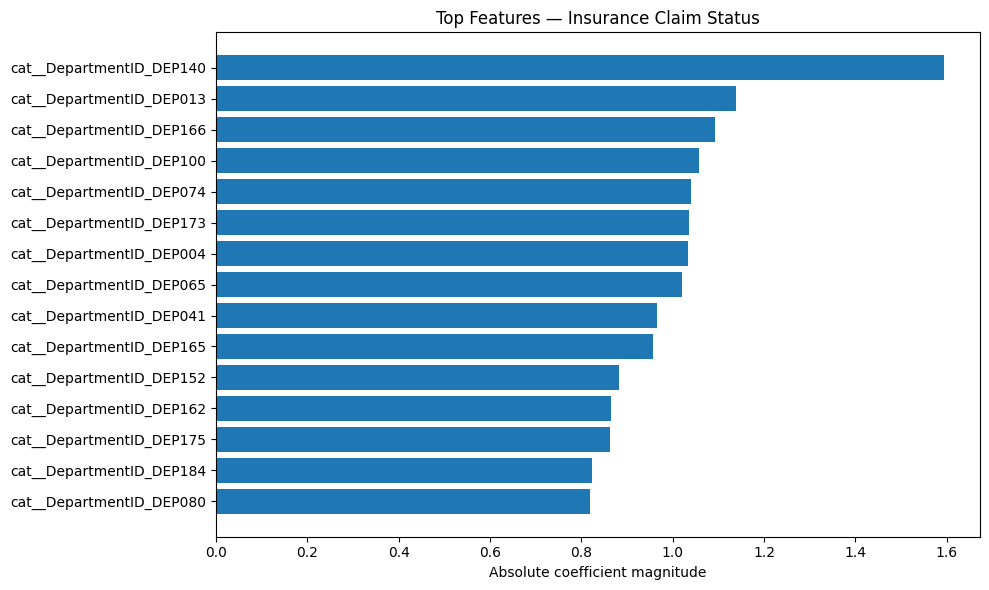


Top 10 features:
                 Feature  Importance
cat__DepartmentID_DEP140    1.593478
cat__DepartmentID_DEP013    1.139779
cat__DepartmentID_DEP166    1.091917
cat__DepartmentID_DEP100    1.058796
cat__DepartmentID_DEP074    1.039372
cat__DepartmentID_DEP173    1.035603
cat__DepartmentID_DEP004    1.034191
cat__DepartmentID_DEP065    1.020813
cat__DepartmentID_DEP041    0.965655
cat__DepartmentID_DEP165    0.958083

--- Patient Satisfaction ---
model: Pipeline
  prep: ColumnTransformer
  model: LogisticRegression


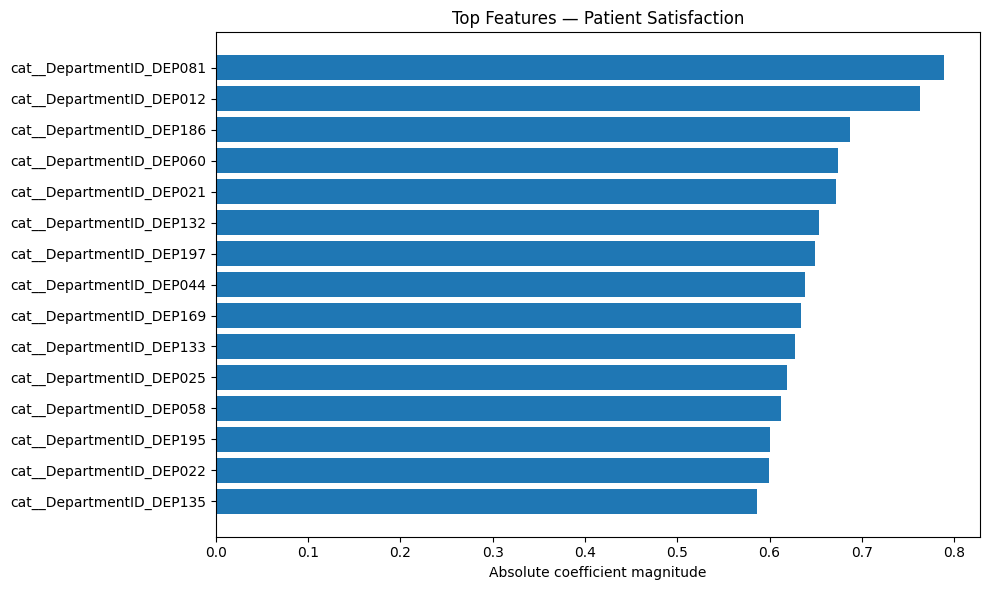


Top 10 features:
                 Feature  Importance
cat__DepartmentID_DEP081    0.788732
cat__DepartmentID_DEP012    0.762757
cat__DepartmentID_DEP186    0.687142
cat__DepartmentID_DEP060    0.673804
cat__DepartmentID_DEP021    0.672402
cat__DepartmentID_DEP132    0.653130
cat__DepartmentID_DEP197    0.649540
cat__DepartmentID_DEP044    0.638422
cat__DepartmentID_DEP169    0.634536
cat__DepartmentID_DEP133    0.628028

Feature-importance reports saved in: /content/drive/MyDrive/Week6_HealthConnect/results


In [ ]:


# WEEK 6 — INSPECT SAVED MODELS AND GENERATE FEATURE IMPORTANCE

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

OUT = "/content/drive/MyDrive/Week6_HealthConnect/results"

model_files = {
    "Insurance Claim Status":
        "insurance_claim_status_prediction_best_model.joblib",
    "Patient Satisfaction":
        "patient_satisfaction_prediction_best_model.joblib"
}

def inspect_model(obj, prefix="model", depth=0):
    """Print nested model structure without assuming pipeline layout."""
    print("  " * depth + f"{prefix}: {type(obj).__name__}")
    if depth >= 3:
        return
    if hasattr(obj, "named_steps"):
        for name, step in obj.named_steps.items():
            inspect_model(step, name, depth + 1)
    elif hasattr(obj, "steps"):
        for name, step in obj.steps:
            inspect_model(step, name, depth + 1)
    elif hasattr(obj, "estimators_") and isinstance(
        getattr(obj, "estimators_", None), list
    ):
        print("  " * (depth + 1) + "Ensemble estimators available")

def find_estimator(obj):
    """Find an estimator that exposes coefficients or feature importances."""
    if hasattr(obj, "feature_importances_") or hasattr(obj, "coef_"):
        return obj
    if hasattr(obj, "named_steps"):
        for step in reversed(list(obj.named_steps.values())):
            result = find_estimator(step)
            if result is not None:
                return result
    if hasattr(obj, "steps"):
        for _, step in reversed(obj.steps):
            result = find_estimator(step)
            if result is not None:
                return result
    return None

reports = []

for task, filename in model_files.items():
    path = os.path.join(OUT, filename)
    if not os.path.exists(path):
        print(f"\nMissing model file: {filename}")
        continue

    saved = joblib.load(path)
    print(f"\n--- {task} ---")
    inspect_model(saved)

    estimator = find_estimator(saved)
    if estimator is None:
        print("No supported estimator found; inspect the model structure above.")
        continue

    if hasattr(estimator, "feature_importances_"):
        scores = np.asarray(estimator.feature_importances_)
        method = "Tree feature importance"
    else:
        coef = np.asarray(estimator.coef_)
        scores = np.mean(np.abs(coef), axis=0) if coef.ndim > 1 else np.abs(coef)
        method = "Absolute coefficient magnitude"

    # Recover feature names if the saved object exposes a fitted preprocessor.
    feature_names = None
    if hasattr(saved, "named_steps"):
        for step in saved.named_steps.values():
            if hasattr(step, "get_feature_names_out"):
                try:
                    feature_names = list(step.get_feature_names_out())
                    if len(feature_names) == len(scores):
                        break
                except Exception:
                    pass

    if feature_names is None or len(feature_names) != len(scores):
        feature_names = [f"Feature_{i+1}" for i in range(len(scores))]
        print("Original feature names unavailable; using numbered feature names.")

    report = pd.DataFrame({
        "Task": task,
        "Feature": feature_names,
        "Importance": scores,
        "Method": method
    }).sort_values("Importance", ascending=False)

    safe_name = task.lower().replace(" ", "_")
    report.to_csv(
        os.path.join(OUT, safe_name + "_feature_importance.csv"),
        index=False
    )
    reports.append(report)

    top = report.head(15).sort_values("Importance")
    plt.figure(figsize=(10, 6))
    plt.barh(top["Feature"], top["Importance"])
    plt.title(f"Top Features — {task}")
    plt.xlabel(method)
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUT, safe_name + "_feature_importance.png"),
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    print("\nTop 10 features:")
    print(report[["Feature", "Importance"]].head(10).to_string(index=False))

if reports:
    pd.concat(reports, ignore_index=True).to_csv(
        os.path.join(OUT, "combined_feature_importance.csv"),
        index=False
    )
    print("\nFeature-importance reports saved in:", OUT)
else:
    print(
        "\nNo feature-importance report could be generated. "
        "The printed model structures will show what needs adapting."
    )


In [ ]:

import os
import pandas as pd

OUT = "/content/drive/MyDrive/Week6_HealthConnect/results"

files_to_review = {
    "Classification comparison": "classification_model_comparison.csv",
    "High-risk proxy comparison": "high_risk_proxy_model_comparison.csv",
    "Regression metrics": "regression_metrics.csv",
    "Combined feature importance": "combined_feature_importance.csv",
}

sections = []

for title, filename in files_to_review.items():
    path = os.path.join(OUT, filename)
    print("\n" + "=" * 65)
    print(title)
    print("=" * 65)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(df.head(20).to_string(index=False))
        sections.append((title, df))
    else:
        print("Not found:", filename)

report_path = os.path.join(OUT, "week6_progress_review.txt")

with open(report_path, "w", encoding="utf-8") as f:
    f.write("HEALTHCONNECT RWANDA — WEEK 6 PROGRESS REVIEW\n\n")
    f.write(
        "Note: feature importance indicates model reliance, not causation. "
        "High-risk proxy results are not clinical validation. "
        "Revenue metrics require leakage checks before being reported as "
        "evidence of generalization.\n\n"
    )

    for title, df in sections:
        f.write("\n" + "=" * 60 + "\n")
        f.write(title + "\n")
        f.write("=" * 60 + "\n")
        f.write(df.to_string(index=False))
        f.write("\n")

print("\nProgress report saved to:", report_path)



Classification comparison
                     Task               Model  Accuracy  Precision_weighted  Recall_weighted  F1_weighted
High Risk Screening Proxy Logistic Regression     0.763            0.873196            0.763     0.800318
High Risk Screening Proxy       Decision Tree     0.673            0.904835            0.673     0.732103
High Risk Screening Proxy       Random Forest     0.885            0.783225            0.885     0.831008

High-risk proxy comparison
                     Task               Model  Accuracy  Precision_weighted  Recall_weighted  F1_weighted
High Risk Screening Proxy Logistic Regression     0.763            0.873196            0.763     0.800318
High Risk Screening Proxy       Decision Tree     0.673            0.904835            0.673     0.732103
High Risk Screening Proxy       Random Forest     0.885            0.783225            0.885     0.831008

Regression metrics
                          Target                   Model          MAE        

In [ ]:

import os
import pandas as pd
import numpy as np

OUT = "/content/drive/MyDrive/Week6_HealthConnect/results"
os.makedirs(OUT, exist_ok=True)

# 1. Inspect regression target and potential leakage
data_path = os.path.join(
    OUT, "cleaned_feature_engineered_appointments.csv"
)
df = pd.read_csv(data_path, low_memory=False)

print("=" * 65)
print("A. BILLING TARGET AND POSSIBLE LEAKAGE")
print("=" * 65)

billing_candidates = [
    c for c in df.columns
    if any(term in c.lower() for term in [
        "billing", "paymentamount", "totalpayment",
        "amountpaid", "claimamount", "revenue"
    ])
]
print("Potential billing-related columns:", billing_candidates)

target_candidates = [
    c for c in df.columns
    if c.lower() in [
        "totalbillingamount", "billingamount",
        "totalamount", "amountbilled", "billing_total"
    ]
]
if target_candidates:
    target_col = target_candidates[0]
    print("Regression target:", target_col)
    print("Target summary:")
    print(df[target_col].describe().to_string())
else:
    print("Could not identify the billing target automatically.")

# 2. Recover saved confusion-matrix summaries
print("\n" + "=" * 65)
print("B. SAVED CLASSIFICATION CONFUSION MATRICES")
print("=" * 65)

for filename in [
    "insurance_claim_status_prediction_confusion_matrix.csv",
    "patient_satisfaction_prediction_confusion_matrix.csv",
    "confusion_matrix_high_risk_proxy.csv"
]:
    path = os.path.join(OUT, filename)
    if os.path.exists(path):
        print("\n", filename)
        print(pd.read_csv(path, index_col=0).to_string())
    else:
        print("\nMissing:", filename)

# 3. Create a truthful task status summary
status = pd.DataFrame([
    ["Data integration", "Completed", "Integrated appointment dataset saved"],
    ["Insurance claim classification", "Model trained", "Review its confusion matrix and metrics"],
    ["Patient satisfaction classification", "Model trained", "Earlier accuracy was approximately 37%; report limitations"],
    ["High-risk screening proxy", "Needs caution", "Rule-generated target; lower-priority recall was zero"],
    ["Billing regression", "Leakage check needed", "Appointment-level billing target; R2 alone is insufficient"],
    ["Patient clustering", "Completed", "Cluster labels are exploratory"],
    ["Facility clustering", "Completed", "Cluster labels are exploratory"],
    ["Billing anomaly detection", "Completed", "150 records flagged; not confirmed fraud"],
    ["Admission prediction", "Unavailable", "No explicit admission outcome identified"],
    ["Length-of-stay prediction", "Unavailable", "No explicit length-of-stay target identified"],
    ["SHAP/LIME explanations", "Not completed", "Feature importance is not SHAP/LIME"],
    ["Executive summary and slides", "Pending", "Prepare from verified results"]
], columns=["Task", "Status", "Notes"])

status_path = os.path.join(OUT, "week6_final_task_status.csv")
status.to_csv(status_path, index=False)

print("\n" + "=" * 65)
print("C. TASK STATUS")
print("=" * 65)
print(status.to_string(index=False))
print("\nSaved:", status_path)


A. BILLING TARGET AND POSSIBLE LEAKAGE
Potential billing-related columns: ['BillingAmount', 'BillingCount', 'BillingStatus', 'ClaimAmount']
Regression target: BillingAmount
Target summary:
count      5000.00000
mean     154226.68780
std       83630.75017
min       10084.00000
25%       81148.75000
50%      153724.00000
75%      226674.75000
max      299968.00000

B. SAVED CLASSIFICATION CONFUSION MATRICES

 insurance_claim_status_prediction_confusion_matrix.csv
          Approved  Pending
Approved       175      180
Pending        174      176

 patient_satisfaction_prediction_confusion_matrix.csv
        High  Low  Medium
High      52   44      34
Low       39   58      47
Medium    35   24      19

 confusion_matrix_high_risk_proxy.csv
                           Higher screening priority  Lower screening priority
Higher screening priority                        885                         0
Lower screening priority                         115                         0

C. TASK STATUS

In [ ]:

import os
import numpy as np
import pandas as pd

path = "/content/drive/MyDrive/Week6_HealthConnect/results/cleaned_feature_engineered_appointments.csv"
df = pd.read_csv(path, low_memory=False)

target = "BillingAmount"

print("BILLING REGRESSION — LEAKAGE AUDIT")
print("=" * 55)

if target not in df.columns:
    print(f"Target column {target!r} not found.")
else:
    y = pd.to_numeric(df[target], errors="coerce")

    related = [
        c for c in df.columns
        if c != target and any(
            word in c.lower()
            for word in [
                "billing", "claimamount", "paymentamount",
                "totalpayment", "amountpaid", "revenue"
            ]
        )
    ]

    print("\nRelated columns:")
    print(related)

    print("\nCorrelation with BillingAmount:")
    for col in related:
        x = pd.to_numeric(df[col], errors="coerce")
        valid = x.notna() & y.notna()

        if valid.sum() > 2 and x[valid].nunique() > 1:
            corr = x[valid].corr(y[valid])
            print(f"{col}: correlation = {corr:.4f}")

        if valid.sum() > 0:
            exact = np.isclose(
                x[valid].to_numpy(),
                y[valid].to_numpy(),
                equal_nan=False
            )
            print(
                f"  Exact matches to BillingAmount: "
                f"{exact.sum()}/{len(exact)}"
            )

    print("\nPotentially suspicious fields:")
    print("Check fields that are calculated from the bill itself,")
    print("payments made after billing, or claims based on the bill.")
    print("A high correlation alone does not prove leakage.")

    numeric = df.select_dtypes(include=np.number)
    correlations = numeric.corr()[target].drop(target)
    print("\nTop 15 numeric correlations with BillingAmount:")
    print(correlations.abs().sort_values(ascending=False).head(15).to_string())


BILLING REGRESSION — LEAKAGE AUDIT

Related columns:
['BillingCount', 'BillingStatus', 'ClaimAmount']

Correlation with BillingAmount:
  Exact matches to BillingAmount: 0/5000
ClaimAmount: correlation = 0.9293
  Exact matches to BillingAmount: 0/3521

Potentially suspicious fields:
Check fields that are calculated from the bill itself,
payments made after billing, or claims based on the bill.
A high correlation alone does not prove leakage.

Top 15 numeric correlations with BillingAmount:
ClaimAmount             0.929350
TotalPaid               0.908430
MeanRating              0.029355
MaxSeverity             0.018544
VisitMonth              0.017487
WeightKg                0.014288
ClaimCount              0.013269
SevereDiagnosisCount    0.013060
FacilityVisitCount      0.012308
HeightCm                0.009556
DoctorExperience        0.007098
BMI                     0.004710
FeedbackCount           0.003066
Age                     0.002509
DoctorWorkload          0.002243


In [ ]:

%pip install -q python-docx python-pptx


In [ ]:

# ============================================================
# HEALTHCONNECT RWANDA — FINAL DELIVERABLES
# Run this ONE cell in Google Colab. No model retraining.
# ============================================================

from pathlib import Path
import os, textwrap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from docx import Document
from docx.shared import Inches as DocInches, Pt
from pptx import Presentation
from pptx.util import Inches, Pt as PPTPt
from pptx.enum.text import PP_ALIGN
from pptx.enum.shapes import MSO_SHAPE
from pptx.dml.color import RGBColor

BASE = Path("/content/drive/MyDrive/Week6_HealthConnect")
OUT = BASE / "results"
OUT.mkdir(parents=True, exist_ok=True)

def read_csv(name):
    p = OUT / name
    return pd.read_csv(p) if p.exists() else pd.DataFrame()

# ---------- 1. Consolidate existing results ----------
claim = read_csv("classification_model_comparison.csv")
proxy = read_csv("high_risk_proxy_model_comparison.csv")
reg = read_csv("regression_metrics.csv")
status = read_csv("week6_final_task_status.csv")
claim_cm = read_csv("insurance_claim_status_prediction_confusion_matrix.csv")
satisfaction_cm = read_csv("patient_satisfaction_prediction_confusion_matrix.csv")
claim_imp = read_csv("insurance_claim_status_feature_importance.csv")
satisfaction_imp = read_csv("patient_satisfaction_feature_importance.csv")

# A transparent summary of results already reported in the notebook.
summary = pd.DataFrame([
    ["Insurance claim status", "Logistic Regression", 0.498,
     "Confusion matrix: 351/705 correct. Weak predictive performance."],
    ["Patient satisfaction", "Logistic Regression", 0.366,
     "Confusion matrix: 129/352 correct. Weak predictive performance."],
    ["High-risk screening proxy", "Random Forest", 0.885,
     "Rule-generated label, not clinical risk. Model predicted every test case as higher priority."],
    ["Billing amount regression", "Random Forest Regressor", 0.940828,
     "Reported R². Treat as preliminary because possible feature leakage has not been ruled out."],
    ["Billing anomaly detection", "Isolation Forest", np.nan,
     "150 of 5,000 records flagged (3%); unusual amounts are not confirmed fraud."],
    ["Patient clustering", "Unsupervised clustering", np.nan,
     "Exploratory segmentation only; clusters are not diagnoses."],
    ["Facility clustering", "Unsupervised clustering", np.nan,
     "Exploratory segmentation only; clusters are not facility quality rankings."]
], columns=["Task", "Method", "Reported_accuracy_or_R2", "Interpretation"])

summary.to_csv(OUT / "final_results_summary.csv", index=False)

# ---------- 2. Architecture diagram ----------
fig, ax = plt.subplots(figsize=(11, 6))
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")

boxes = [
    (0.5, 7.5, 2.5, 1.2, "Source data\nPatients • Visits • Billing"),
    (3.8, 7.5, 2.5, 1.2, "Data preparation\nCleaning • Integration"),
    (7.0, 7.5, 2.5, 1.2, "Feature engineering\nValidated data tables"),
    (0.5, 4.5, 2.5, 1.3, "Classification\nClaims • Satisfaction"),
    (3.8, 4.5, 2.5, 1.3, "Analytics\nRegression • Clustering"),
    (7.0, 4.5, 2.5, 1.3, "Anomaly screening\nUnusual billing records"),
    (2.1, 1.4, 2.5, 1.3, "Explainability\nFeature importance"),
    (5.5, 1.4, 2.5, 1.3, "Dashboard / Reports\nHuman-reviewed insights")
]
for x, y, w, h, label in boxes:
    ax.add_patch(plt.Rectangle((x,y),w,h,fill=False,linewidth=1.5))
    ax.text(x+w/2,y+h/2,label,ha="center",va="center",fontsize=9)

def arrow(a,b):
    ax.annotate("", xy=b, xytext=a,
                arrowprops=dict(arrowstyle="->", linewidth=1.2))

arrow((3.0,8.1),(3.8,8.1))
arrow((6.3,8.1),(7.0,8.1))
arrow((8.25,7.5),(1.75,5.8))
arrow((8.25,7.5),(5.05,5.8))
arrow((8.25,7.5),(8.25,5.8))
arrow((1.75,4.5),(3.1,2.7))
arrow((5.05,4.5),(6.7,2.7))
arrow((8.25,4.5),(6.7,2.7))
ax.set_title("Proposed HealthConnect Rwanda Analytics Architecture", fontsize=14)
architecture_png = OUT / "deployment_architecture.png"
plt.savefig(architecture_png, dpi=180, bbox_inches="tight")
plt.close()

# ---------- 3. Executive summary document ----------
doc = Document()
sec = doc.sections[0]
sec.top_margin = DocInches(0.65)
sec.bottom_margin = DocInches(0.65)
sec.left_margin = DocInches(0.75)
sec.right_margin = DocInches(0.75)

styles = doc.styles
styles["Normal"].font.name = "Arial"
styles["Normal"].font.size = Pt(9)
for s in ["Title", "Heading 1", "Heading 2"]:
    styles[s].font.name = "Arial"

doc.add_heading("AI-Powered Clinical Risk Prediction and Healthcare Intelligence System", 0)
doc.add_paragraph("HealthConnect Rwanda | Week 6 Machine Learning Project")
doc.add_paragraph("Executive Summary | Educational prototype using synthetic project data")

doc.add_heading("1. Project overview", level=1)
doc.add_paragraph(
    "This project explores how machine learning and data analytics can organize healthcare "
    "information into useful operational insights. The workflow integrates appointment-level "
    "information with related patient, billing, feedback and insurance data where available. "
    "It then demonstrates classification, regression, clustering, anomaly screening and "
    "feature-importance analysis."
)
doc.add_paragraph(
    "The intended users are healthcare administrators, analysts and operational teams who "
    "need accessible summaries rather than raw tables. The work is a prototype, not a deployed "
    "clinical decision system. The available data and model performance do not justify using "
    "its outputs to diagnose patients, determine treatment or deny services."
)
doc.add_heading("Project objectives", level=2)
for x in [
    "Prepare and integrate available healthcare datasets.",
    "Explore prediction of insurance claim status and patient satisfaction.",
    "Demonstrate a rule-generated screening-priority proxy and billing-amount regression.",
    "Explore patient and facility clusters and unusual billing records.",
    "Present results, limitations, explainability and a proposed deployment architecture."
]:
    doc.add_paragraph(x, style="List Bullet")

doc.add_heading("2. Methods and results", level=1)
doc.add_paragraph(
    "Data preparation and feature engineering produced an appointment-level analytical dataset "
    "with approximately 5,000 records and 49 columns. The workflow also saved model comparison "
    "tables, confusion matrices, feature-importance outputs, clustering assignments and billing "
    "anomaly flags."
)
t = doc.add_table(rows=1, cols=3)
t.style = "Light Shading Accent 1"
for i,v in enumerate(["Task", "Reported result", "Interpretation"]):
    t.rows[0].cells[i].text = v
rows = [
    ("Insurance claim status", "49.8% accuracy",
     "Logistic Regression; weak performance on the test set."),
    ("Patient satisfaction", "36.6% accuracy",
     "Logistic Regression; weak performance across satisfaction classes."),
    ("High-risk screening proxy", "88.5% accuracy",
     "Not a clinical risk model; the Random Forest predicted all test cases as higher priority."),
    ("Billing amount regression", "R² = 0.941 reported",
     "Preliminary only; potential leakage from related billing/claim variables has not been ruled out."),
    ("Billing anomaly screening", "150 of 5,000 flagged",
     "Isolation Forest flagged 3% as unusual; these are not confirmed fraud cases."),
    ("Clustering", "Patient and facility clusters saved",
     "Exploratory patterns requiring domain interpretation.")
]
for row in rows:
    cells = t.add_row().cells
    for i,v in enumerate(row):
        cells[i].text = v

doc.add_paragraph(
    "Feature-importance files were generated from logistic-regression coefficients. Several of "
    "the largest coefficients correspond to department identifiers. These signals may reflect "
    "category-specific patterns and should not be interpreted as causal effects. SHAP and LIME "
    "explanations have not yet been generated."
)

doc.add_page_break()
doc.add_heading("3. Interpretation and operational value", level=1)
doc.add_paragraph(
    "The main contribution is an integrated analytical workflow that demonstrates how healthcare "
    "data can be transformed into reusable tables, baseline models and operational summaries. "
    "The saved outputs can support further analysis and help stakeholders identify where better "
    "data or improved modelling is needed."
)
doc.add_heading("Potential uses after further validation", level=2)
for x in [
    "Monitor data completeness and consistency across patient, appointment, billing and claim records.",
    "Review claim-status patterns and satisfaction feedback as operational indicators.",
    "Investigate unusual billing records with authorized finance staff.",
    "Explore patient or facility segments to formulate questions for further analysis.",
    "Provide a dashboard with filters, trends, model limitations and links to underlying records."
]:
    doc.add_paragraph(x, style="List Bullet")

doc.add_heading("4. Limitations and responsible use", level=1)
limitations = [
    "The project data are synthetic or educational and are not evidence of real-world clinical effectiveness.",
    "No explicit, reliable hospital-admission outcome was identified in the available tables.",
    "No suitable length-of-stay target was identified, so a valid length-of-stay model could not be completed.",
    "No laboratory-results table was identified in the reviewed dataset inventory.",
    "The high-priority label was generated using a rule; it is not an independently verified clinical outcome.",
    "The high-risk proxy model's confusion matrix indicates it classified all test examples as higher priority, so its accuracy is misleading.",
    "The billing regression predicts appointment-level BillingAmount, not future monthly hospital revenue. Related billing or claim variables may cause target leakage.",
    "Satisfaction prediction performance is weak and should not be used for individual decisions.",
    "Anomaly flags identify unusual records, not confirmed fraud, errors or misconduct.",
    "Clustering is exploratory. SHAP/LIME and validated clinical/geographic assessments are not complete."
]
for x in limitations:
    doc.add_paragraph(x, style="List Bullet")

doc.add_paragraph(
    "Ethical safeguards: keep a human reviewer in the decision loop; restrict access to sensitive "
    "records; document data provenance; assess performance across relevant groups; communicate "
    "uncertainty; and never use this prototype alone to make clinical, insurance eligibility or "
    "patient-access decisions."
)

doc.add_page_break()
doc.add_heading("5. Proposed deployment architecture", level=1)
doc.add_paragraph(
    "The proposed architecture separates source data, preparation, modelling and user-facing "
    "reporting. The current project has produced local/Drive artifacts; this diagram describes "
    "a future deployment design, not a live deployed service."
)
doc.add_picture(str(architecture_png), width=DocInches(6.6))
doc.add_heading("Recommended next steps", level=2)
for x in [
    "Confirm the permitted use, provenance and meaning of every source field.",
    "Resolve leakage risks before reporting regression performance as reliable.",
    "Use appropriate train/test separation and class-wise metrics for classification.",
    "Obtain valid admission and length-of-stay outcomes before modelling those targets.",
    "Add SHAP or LIME only after selecting and reviewing a suitable model.",
    "Build a dashboard with clear model limitations, timestamps, filters and human review.",
    "Conduct privacy, fairness, security and domain-expert reviews before any real-world pilot."
]:
    doc.add_paragraph(x, style="List Bullet")

doc.add_page_break()
doc.add_heading("6. Conclusion", level=1)
doc.add_paragraph(
    "HealthConnect Rwanda demonstrates a broad machine-learning workflow across healthcare "
    "operations data. The integration, saved baseline models, exploratory clustering, anomaly "
    "screening and reporting artifacts provide a foundation for continued development. However, "
    "the classification results are weak, the screening proxy is not clinically validated, and "
    "the billing regression needs a leakage review. Missing targets also prevent defensible "
    "admission and length-of-stay prediction."
)
doc.add_paragraph(
    "The appropriate conclusion is that this is an educational analytics prototype with useful "
    "technical outputs, not a validated clinical system. Future work should prioritize trustworthy "
    "targets, leakage-free evaluation, transparent explanations, data governance and human oversight."
)
doc.add_heading("Deliverables produced", level=2)
for x in [
    "Cleaned and feature-engineered appointment dataset",
    "Classification and regression result tables",
    "Confusion matrices and feature-importance outputs",
    "Patient and facility cluster assignments",
    "Billing anomaly screening output",
    "Limitations and ethics notes",
    "Proposed deployment architecture diagram",
    "Executive summary and presentation"
]:
    doc.add_paragraph(x, style="List Bullet")

docx_path = OUT / "HealthConnect_Executive_Summary.docx"
doc.save(docx_path)

# ---------- 4. Create 12-slide presentation ----------
prs = Presentation()
prs.slide_width = Inches(13.333)
prs.slide_height = Inches(7.5)

def add_slide(title, bullets=None, image=None, subtitle=None):
    slide = prs.slides.add_slide(prs.slide_layouts[6])
    # title
    tx = slide.shapes.add_textbox(Inches(0.6), Inches(0.35), Inches(12.1), Inches(0.7))
    p = tx.text_frame.paragraphs[0]
    p.text = title
    p.font.size = PPTPt(27); p.font.bold = True
    p.font.color.rgb = RGBColor(31, 78, 121)

    if subtitle:
        st = slide.shapes.add_textbox(Inches(0.65), Inches(1.15), Inches(12), Inches(0.45))
        st.text_frame.text = subtitle
        st.text_frame.paragraphs[0].font.size = PPTPt(15)

    if image:
        slide.shapes.add_picture(str(image), Inches(1.0), Inches(1.35),
                                 width=Inches(11.3), height=Inches(5.55))
    elif bullets:
        box = slide.shapes.add_textbox(Inches(0.85), Inches(1.35), Inches(11.6), Inches(5.7))
        tf = box.text_frame
        tf.word_wrap = True
        for i, bullet in enumerate(bullets):
            p = tf.paragraphs[0] if i == 0 else tf.add_paragraph()
            p.text = bullet
            p.level = 0
            p.font.size = PPTPt(20)
            p.space_after = PPTPt(13)
    # simple footer
    ft = slide.shapes.add_textbox(Inches(0.65), Inches(7.12), Inches(12), Inches(0.2))
    ft.text_frame.text = "HealthConnect Rwanda | Educational prototype"
    ft.text_frame.paragraphs[0].font.size = PPTPt(9)
    return slide

add_slide("HealthConnect Rwanda",
          ["AI-Powered Clinical Risk Prediction and Healthcare Intelligence System",
           "Week 6 Machine Learning Project",
           "An educational prototype using synthetic project data"])

add_slide("Project objectives", [
    "Integrate and prepare available healthcare datasets.",
    "Build baseline classification and regression models where targets are available.",
    "Explore patient/facility clustering and unusual billing records.",
    "Communicate model performance, explainability, ethics and limitations."
])

add_slide("Data preparation", [
    "Integrated appointment-level analytical dataset: approximately 5,000 rows and 49 columns.",
    "Project tables include patient, clinical transaction, billing, feedback and insurance information.",
    "Saved reusable outputs include cleaned data, model results, clusters and anomaly flags.",
    "Only fields and targets supported by available data were used."
])

add_slide("Classification results", [
    "Insurance claim status: Logistic Regression accuracy approximately 49.8%.",
    "Patient satisfaction: Logistic Regression accuracy approximately 36.6%.",
    "Both results indicate limited predictive performance on the evaluated test sets.",
    "These models require improvement and should not guide individual decisions."
])

add_slide("High-risk screening proxy", [
    "The target was generated from a simple rule, not an observed clinical outcome.",
    "Random Forest reported 88.5% accuracy, but predicted every test case as higher priority.",
    "The model failed to distinguish the lower-priority test cases.",
    "This result is not evidence of clinical risk-prediction ability."
])

add_slide("Billing regression", [
    "Target: appointment-level BillingAmount.",
    "Reported Random Forest R²: approximately 0.941; reported MAE: approximately 8,535.",
    "Possible leakage from related billing/claim variables has not been ruled out.",
    "Treat these metrics as preliminary, not as a reliable forecast of future hospital revenue."
])

add_slide("Clustering and anomaly screening", [
    "Patient and facility cluster assignments were saved for exploratory analysis.",
    "Isolation Forest flagged 150 of 5,000 billing records as unusual (3%).",
    "Anomaly flags require investigation and do not prove fraud or billing errors.",
    "Clusters are exploratory groups, not diagnoses or facility quality rankings."
])

add_slide("Explainability", [
    "Feature-importance outputs were generated from logistic-regression coefficients.",
    "Department identifiers appeared among the strongest coefficient magnitudes.",
    "Coefficient magnitude does not establish causation or a reliable explanation for an individual.",
    "SHAP/LIME analyses remain incomplete."
])

add_slide("Key data gaps", [
    "No explicit reliable hospital-admission outcome identified.",
    "No suitable length-of-stay target identified.",
    "No laboratory-results table identified in the reviewed data inventory.",
    "These tasks must remain documented gaps rather than fabricated model results."
])

add_slide("Proposed architecture", image=architecture_png)

add_slide("Ethics and responsible use", [
    "The dataset is synthetic/educational; findings are not clinical evidence.",
    "Protect sensitive data and limit access by role.",
    "Review fairness and performance across relevant groups.",
    "Keep human oversight and communicate uncertainty.",
    "Do not use this prototype alone for treatment, eligibility or patient-access decisions."
])

add_slide("Recommendations and conclusion", [
    "Prioritize leakage-free evaluation and improve weak classification models.",
    "Obtain valid admission and length-of-stay outcomes before modelling those targets.",
    "Complete explainability and domain-expert review before any real-world pilot.",
    "The project provides an analytical foundation, not a validated clinical decision system."
])

pptx_path = OUT / "HealthConnect_Final_Presentation.pptx"
prs.save(pptx_path)

# ---------- 5. Final file list ----------
print("\nDONE — FINAL DELIVERABLES SAVED")
for p in [
    docx_path,
    pptx_path,
    OUT / "final_results_summary.csv",
    architecture_png
]:
    print(f"{p.name}: {'OK' if p.exists() else 'NOT FOUND'}")
print("\nFolder:", OUT)



DONE — FINAL DELIVERABLES SAVED
HealthConnect_Executive_Summary.docx: OK
HealthConnect_Final_Presentation.pptx: OK
final_results_summary.csv: OK
deployment_architecture.png: OK

Folder: /content/drive/MyDrive/Week6_HealthConnect/results
